# Exploratory analysis — Boston (A) and Jersey City (B)

Team **Snusik** · region **US Northeast** · Inside Airbnb detailed `listings.csv.gz`.

This notebook is reproducible: it downloads the two pinned snapshots if they are not present,
and runs both on Databricks (reads the raw files from the bronze landing volume) and locally.
City C (New York) is deliberately **not** loaded here — it stays unseen until the pipeline and
model for A and B are finished.

## 0. Summary

**What we now know**

* **Size and grain.** 4,368 Boston and 2,330 Jersey City listings; one row = one listing at
  scrape time, `id` unique; both files have the same 90 columns. 14 of them are completely
  empty in this scrape (all host response/acceptance fields, `host_since`, `bathrooms`,
  `instant_bookable`, `neighbourhood_group_cleansed`, ...).
* **The target is missing not at random.** `price` exists for 80% (Boston) / 90% (Jersey City)
  of listings. Two-thirds of records carried over from the previous scrape and 92–100% of
  fully blocked calendars have no price. The priced population is the *active, bookable*
  listings — the population a pricing product serves — and we train/evaluate on it only.
* **Price shape.** Right-skewed: median \$253 (Boston) / \$216 (Jersey City), 99th percentile
  \$1.2–1.3k. Log price is close to symmetric → we model log price.
* **Drivers visible before any model.** Room type (entire home ≈ \$300 vs private room
  \$80–120), capacity (median price rises steadily up to ~10 guests), and the *stay type*:
  a third of priced listings are monthly rentals (minimum stay ≥ 28 nights) whose nightly
  price is less than half that of short-stay listings.
* **Outliers.** 7 implausible prices (≥ \$750 per guest per night — placeholder/"parking"
  prices such as a 2-bedroom at \$11,680) are excluded; 47 extreme but plausible luxury homes
  are kept.
* **Leakage.** Six columns are functions of the target: the three `price_quote_*` value
  columns, the two quote dates, and `estimated_revenue_l365d` (= price × occupancy, exact to
  rounding for 100% of priced rows). Booking outcomes (availability, occupancy, recent review
  counts) are excluded from the model as soft leaks.
* **The two cities differ.** Jersey City private rooms are much cheaper (median \$80 vs \$119);
  Boston has hotel rooms, Jersey City has none; Boston has 25 neighbourhoods, Jersey City 6
  council wards.

**What we still do not know**

* Whether the advertised `price` is what guests pay: it excludes cleaning fees and taxes, and
  we have no booking/transaction data.
* Seasonality: one snapshot per city, taken in September (peak season in Boston).
* Why ~9% (Boston) / 5% (Jersey City) of *current, bookable* listings still have no price —
  a scraper failure or no quotable dates in the quote window.
* Whether the \$750-per-guest rule and the "monthly = 28+ nights" threshold hold in a market
  with a different price level or different rental rules.
* Whether location features learned here (neighbourhood names, coordinates) mean anything in
  another city — they are, by construction, city-specific.
* How much variance is explained by things we cannot observe (photos, renovation, view).

## 1. Setup and data loading

In [1]:
import json
import os
import re
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

CITIES = {
    # city key: (display name, Inside Airbnb path, snapshot date)
    "boston": ("Boston", "united-states/ma/boston", "2026-09-19"),
    "jersey-city": ("Jersey City", "united-states/nj/jersey-city", "2026-09-21"),
}
URL = "https://data.insideairbnb.com/{path}/{date}/data/listings.csv.gz"

# On Databricks the pipeline lands raw files in a Unity Catalog volume; locally we use ./data/raw.
VOLUME_ROOT = "/Volumes/workspace/airbnb_bronze/raw"
DATA_ROOT = VOLUME_ROOT if os.path.isdir(VOLUME_ROOT) else os.path.abspath(os.path.join(os.getcwd(), "..", "data", "raw"))


def raw_file(city: str) -> str:
    _, path, date = CITIES[city]
    target = os.path.join(DATA_ROOT, city, date, "listings.csv.gz")
    if not os.path.exists(target):
        os.makedirs(os.path.dirname(target), exist_ok=True)
        urllib.request.urlretrieve(URL.format(path=path, date=date), target)
    return target


frames = []
for key, (name, _, date) in CITIES.items():
    f = raw_file(key)
    d = pd.read_csv(f, dtype=str, keep_default_na=True)  # read everything as text, like bronze
    d.insert(0, "city", name)
    d.insert(1, "snapshot_date", date)
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)
print("data root:", DATA_ROOT)
print("raw shape:", raw.shape)

data root: /Users/yuliana/Documents/UCU/BigData/snusik_hw2/data/raw
raw shape: (6698, 92)


Typed working copy. Every conversion here is one the pipeline's silver layer must also apply
(section 6), so the numbers below describe what the model will actually see.

In [2]:
def money(s: pd.Series) -> pd.Series:
    return pd.to_numeric(s.str.replace(r"[$,]", "", regex=True), errors="coerce")


def num(s: pd.Series) -> pd.Series:
    return pd.to_numeric(s, errors="coerce")


def flag(s: pd.Series) -> pd.Series:
    return s.map({"t": True, "f": False})


def bathrooms_from_text(s: pd.Series) -> pd.Series:
    t = s.str.lower()
    n = pd.to_numeric(t.str.extract(r"(\d+(?:\.\d+)?)")[0], errors="coerce")
    return n.where(~t.str.contains("half-bath", na=False), 0.5)


df = raw.copy()
df["price"] = money(raw["price"])
for c in ["accommodates", "bedrooms", "beds", "minimum_nights", "maximum_nights", "availability_30",
          "availability_60", "availability_90", "availability_365", "number_of_reviews",
          "number_of_reviews_ltm", "review_scores_rating", "review_scores_location", "reviews_per_month",
          "calculated_host_listings_count", "estimated_occupancy_l365d", "latitude", "longitude",
          "hosts_time_as_host_years", "price_quote_price_per_night", "price_quote_total_price"]:
    df[c] = num(raw[c])
df["estimated_revenue_l365d"] = money(raw["estimated_revenue_l365d"])
for c in ["host_is_superhost", "host_identity_verified", "host_has_profile_pic", "has_availability"]:
    df[c] = flag(raw[c])
df["bathrooms_parsed"] = bathrooms_from_text(raw["bathrooms_text"])
df["bath_shared"] = raw["bathrooms_text"].str.contains("shared", case=False, na=False)
df["n_amenities"] = raw["amenities"].map(lambda a: len(json.loads(a)) if isinstance(a, str) else np.nan)
df["monthly_stay"] = df["minimum_nights"] >= 28
df["stale_record"] = raw["source"].eq("previous scrape")

## 2. The dataset

**Grain:** one row is one Airbnb listing as seen by the Inside Airbnb scraper during the
snapshot (the scrape spans a few days after the snapshot date, see `last_scraped`). The `id`
is unique within each city file. `price` is the advertised price per night for a near-future
stay quoted by Airbnb at scrape time, in USD.

In [3]:
desc = df.groupby("city").agg(
    snapshot_date=("snapshot_date", "first"),
    first_scraped=("last_scraped", "min"),
    last_scraped=("last_scraped", "max"),
    listings=("id", "size"),
    unique_ids=("id", "nunique"),
    hosts=("host_id", "nunique"),
    neighbourhoods=("neighbourhood_cleansed", "nunique"),
    with_price=("price", "count"),
)
desc["columns"] = raw.shape[1] - 2
desc

,snapshot_date,first_scraped,last_scraped,listings,unique_ids,hosts,neighbourhoods,with_price,columns
city,,,,,,,,,
Boston,2026-09-19,2026-09-19,2026-09-20,4368,4368,1395,25,3486,90
Jersey City,2026-09-21,2026-09-22,2026-09-25,2330,2330,980,6,2094,90


In [4]:
same_schema = list(frames[0].columns) == list(frames[1].columns)
print("Both cities have the same 90 columns in the same order:", same_schema)

Both cities have the same 90 columns in the same order: True


## 3. Profile of the columns we use

### 3.1 Roles and types
Everything arrives as text. The table lists the columns the pipeline keeps, their raw form and
the type they are cast to.

In [5]:
roles = pd.DataFrame([
    ("id", "key", "integer text", "bigint"),
    ("price", "target", "'$1,234.00' text", "double (USD/night)"),
    ("room_type", "feature", "4 categories", "string"),
    ("property_type", "feature", "~30 categories, long tail", "string (top-k + Other)"),
    ("accommodates", "feature / baseline key", "integer text", "int"),
    ("bedrooms, beds", "feature", "numeric text", "double"),
    ("bathrooms_text", "feature", "'1.5 shared baths', 'Half-bath'", "double + shared flag"),
    ("bathrooms", "dropped", "always empty", "-"),
    ("amenities", "feature", "JSON array as text", "array<string> -> count + flags"),
    ("neighbourhood_cleansed", "feature", "25 (Boston) / 6 wards (JC)", "string"),
    ("latitude, longitude", "feature", "decimal text", "double"),
    ("minimum_nights", "feature", "integer text", "int + monthly_stay flag (>=28)"),
    ("host_is_superhost, host_identity_verified", "feature", "'t'/'f'", "boolean"),
    ("calculated_host_listings_count", "feature", "integer text", "int"),
    ("hosts_time_as_host_years", "feature", "integer text", "double"),
    ("number_of_reviews, review_scores_*", "feature", "numeric text", "int / double"),
    ("availability_30/365", "analytics only", "integer text", "int"),
    ("last_scraped, source", "lineage", "date / 'previous scrape'", "date / boolean stale flag"),
], columns=["column", "role", "raw form", "silver type"])
roles

,column,role,raw form,silver type
0,id,key,integer text,bigint
1,price,target,"'$1,234.00' text",double (USD/night)
2,room_type,feature,4 categories,string
3,property_type,feature,"~30 categories, long tail",string (top-k + Other)
4,accommodates,feature / baseline key,integer text,int
5,"bedrooms, beds",feature,numeric text,double
6,bathrooms_text,feature,"'1.5 shared baths', 'Half-bath'",double + shared flag
7,bathrooms,dropped,always empty,-
8,amenities,feature,JSON array as text,array<string> -> count + flags
9,neighbourhood_cleansed,feature,25 (Boston) / 6 wards (JC),string


### 3.2 Missing values

In [6]:
used = ["price", "room_type", "property_type", "accommodates", "bedrooms", "beds", "bathrooms_text",
        "amenities", "neighbourhood_cleansed", "latitude", "longitude", "minimum_nights",
        "host_is_superhost", "host_identity_verified", "calculated_host_listings_count",
        "hosts_time_as_host_years", "number_of_reviews", "review_scores_rating", "review_scores_location",
        "reviews_per_month", "first_review", "has_availability", "availability_365", "license"]
miss = raw.groupby("city")[used].apply(lambda g: g.isna().mean()).T.mul(100).round(1)
miss.columns = [f"% missing {c}" for c in miss.columns]
miss.sort_values(miss.columns[0], ascending=False)

,% missing Boston,% missing Jersey City
license,27.7,40.1
price,20.2,10.1
first_review,18.1,17.8
reviews_per_month,18.1,17.8
review_scores_location,18.1,17.8
review_scores_rating,18.1,17.8
beds,2.8,1.1
minimum_nights,0.9,0.0
bathrooms_text,0.7,0.0
has_availability,0.7,0.5


In [7]:
empty_cols = [c for c in raw.columns if raw[c].isna().all()]
print(f"{len(empty_cols)} columns are 100% empty in BOTH cities:")
print(", ".join(empty_cols))

14 columns are 100% empty in BOTH cities:
neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, neighbourhood_group_cleansed, bathrooms, calendar_updated, instant_bookable


**Pattern 1 — review fields are structurally missing.** Every review score, `first_review`,
`last_review` and `reviews_per_month` is null exactly when `number_of_reviews == 0`. They are
not "unknown"; the listing has never been reviewed. The pipeline keeps the nulls, adds a
`has_reviews` flag, and the model can use the null as information.

In [8]:
pd.crosstab([df["city"], df["number_of_reviews"].eq(0).rename("zero_reviews")],
            df["review_scores_rating"].isna().rename("score_missing"))

score_missing             False  True 
city        zero_reviews              
Boston      False          3579      0
            True              0    789
Jersey City False          1916      0
            True              0    414

**Pattern 2 — the target `price` is missing not at random.** About 20% of Boston and 10% of
Jersey City listings have no price. Missingness is concentrated in (a) *stale* records that the
scraper carried over from the previous scrape (`source = 'previous scrape'`), and (b) listings
whose calendar is fully blocked (`availability_365 = 0`) — Airbnb cannot quote a stay that
cannot be booked. Monthly-stay listings are also more often unpriced.

In [9]:
def miss_rate(by):
    return df.groupby(["city", by])["price"].apply(lambda s: s.isna().mean() * 100).round(1).unstack()


pd.concat({
    "stale record (previous scrape)": miss_rate("stale_record"),
    "calendar fully blocked": miss_rate(df["availability_365"].eq(0).rename("blocked")),
    "monthly stay (min nights >= 28)": miss_rate("monthly_stay"),
}, axis=1)

stale record (previous scrape)       calendar fully blocked        monthly stay (min nights >= 28)      
stale_record                          False True                   False  True                            False True 
city                                                                                                                 
Boston                                  8.8  65.2                   11.2   92.5                             7.3  38.3
Jersey City                             4.6  66.3                    6.1  100.0                             3.2  19.6

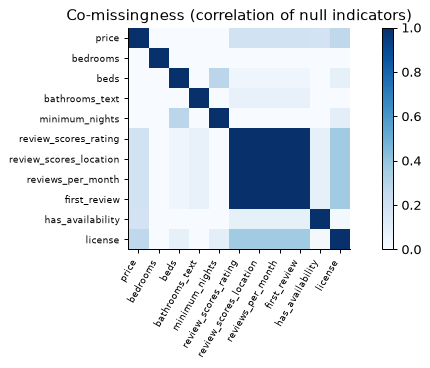

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.2))
na = raw[used].isna()
corr = na.loc[:, na.any()].astype(float).corr()
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
ax.set_title("Co-missingness (correlation of null indicators)")
fig.colorbar(im, ax=ax)
plt.show()

The co-missingness map has one solid block — the review fields (pattern 1). A missing
`license` goes together with having no reviews (≈0.4): new or inactive listings that have not
registered. Price missingness is only weakly related to other nulls (≈0.2 with reviews and
`has_availability`): it is driven by the *record status* (stale, blocked), not by other gaps.
`beds` and `minimum_nights` are missing together in a few Boston rows. `beds` and
`bathrooms_text` are missing for <3% of listings — safe to leave as null (the model handles nulls).

**Consequence for the model:** the model is trained and evaluated only on priced listings.
Those are the *active, bookable* listings, which is also the population a pricing product
serves. Predictions are still written for unpriced listings (as a suggested price), but no
error can be measured on them.

## 4. Distributions
### 4.1 Price

In [11]:
pct = df.groupby("city")["price"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(0)
pct

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
city,,,,,,,,,,,,
Boston,3486.0,315.0,280.0,30.0,42.0,64.0,150.0,253.0,397.0,765.0,1337.0,4815.0
Jersey City,2094.0,274.0,351.0,30.0,40.0,47.0,108.0,216.0,360.0,634.0,1183.0,11680.0


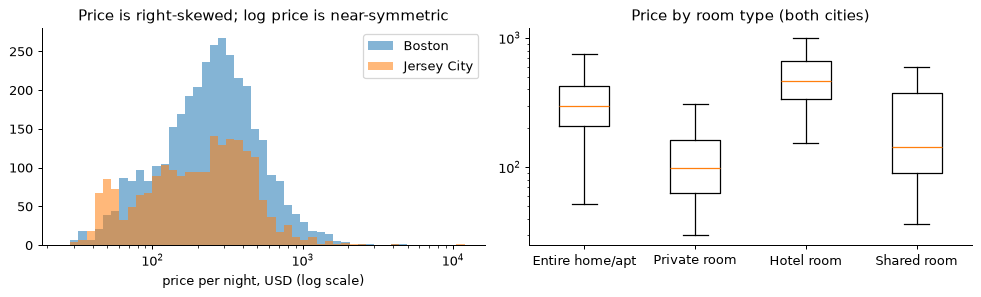

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
bins = np.logspace(np.log10(25), np.log10(12000), 50)
for city, g in df.groupby("city"):
    axes[0].hist(g["price"].dropna(), bins=bins, alpha=0.55, label=city)
axes[0].set_xscale("log")
axes[0].set_xlabel("price per night, USD (log scale)")
axes[0].set_title("Price is right-skewed; log price is near-symmetric")
axes[0].legend()
order = ["Entire home/apt", "Private room", "Hotel room", "Shared room"]
data = [df.loc[df["room_type"].eq(rt), "price"].dropna() for rt in order]
axes[1].boxplot(data, showfliers=False)
axes[1].set_xticks(range(1, len(order) + 1), order)
axes[1].set_yscale("log")
axes[1].set_title("Price by room type (both cities)")
plt.tight_layout()
plt.show()

In [13]:
df.groupby(["city", "room_type"])["price"].agg(["count", "median", "mean"]).round(0)

count  median   mean
city        room_type                            
Boston      Entire home/apt   2391   297.0  364.0
            Hotel room          84   463.0  533.0
            Private room      1007   119.0  181.0
            Shared room          4   302.0  333.0
Jersey City Entire home/apt   1438   300.0  355.0
            Private room       654    80.0   95.0
            Shared room          2    57.0   57.0

Price grows with capacity (`accommodates`) — this is why the baseline is a median per
(room type, accommodates).

In [14]:
df.pivot_table(index="accommodates", columns="city", values="price", aggfunc="median").round(0).head(12).T

accommodates,1,2,3,4,5,6,7,8,9,10,11,12
city,,,,,,,,,,,,
Boston,71.0,211.0,235.0,322.0,350.0,386.0,365.0,450.0,490.0,530.0,460.0,634.0
Jersey City,50.0,109.0,190.0,230.0,296.0,344.0,377.0,389.0,457.0,453.0,493.0,480.0


### 4.2 Nightly vs monthly pricing

A third of priced listings are *monthly-priced*: their minimum stay is 28+ nights and the
`price` is the monthly rate (after Airbnb's monthly discount) divided into nights. Their
nightly price is less than half of a short-stay listing's. `minimum_nights` is therefore a
first-class feature, not a nuisance column.

In [15]:
df.groupby(["city", "monthly_stay"])["price"].agg(["count", "median"]).round(0)

count  median
city        monthly_stay               
Boston      False          2365   311.0
            True           1121   134.0
Jersey City False          1304   299.0
            True            790   107.0

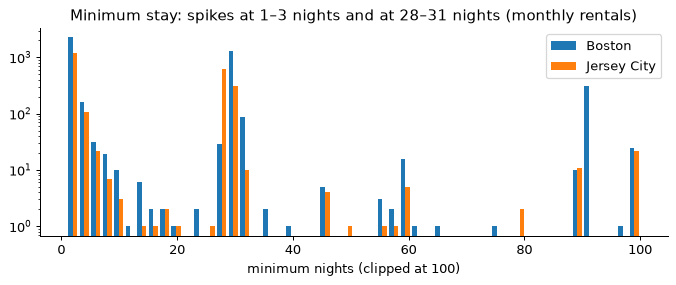

In [16]:
fig, ax = plt.subplots(figsize=(9, 3))
mn = df["minimum_nights"].clip(upper=100)
ax.hist([mn[df["city"].eq(c)].dropna() for c in ["Boston", "Jersey City"]], bins=50, label=["Boston", "Jersey City"])
ax.set_yscale("log")
ax.set_xlabel("minimum nights (clipped at 100)")
ax.set_title("Minimum stay: spikes at 1–3 nights and at 28–31 nights (monthly rentals)")
ax.legend()
plt.show()

### 4.3 Availability

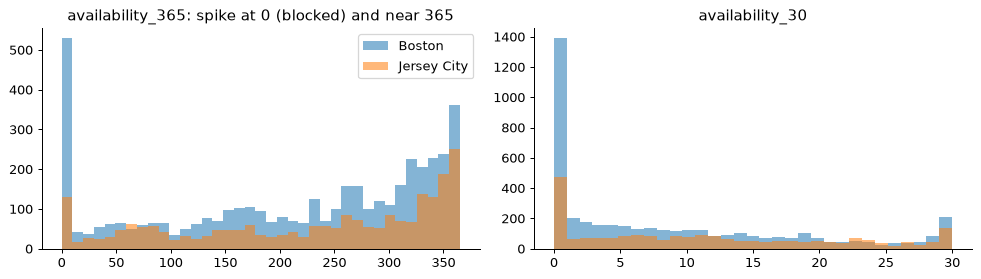

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for city, g in df.groupby("city"):
    axes[0].hist(g["availability_365"], bins=37, alpha=0.55, label=city)
    axes[1].hist(g["availability_30"], bins=31, alpha=0.55, label=city)
axes[0].set_title("availability_365: spike at 0 (blocked) and near 365")
axes[1].set_title("availability_30")
axes[0].legend()
plt.tight_layout()
plt.show()

In [18]:
df.groupby("city")[["availability_30", "availability_365"]].agg(["median", "mean"]).round(0)

availability_30       availability_365       
                     median  mean           median   mean
city                                                     
Boston                  5.0   9.0            243.0  212.0
Jersey City            10.0  11.0            262.0  227.0

## 5. Outliers and how we classify them

Inspecting the most expensive listings shows two different things:

* **Implausible prices** — e.g. a 2-bedroom home for 6 guests at \$11,680/night with zero reviews,
  a hotel *private room* for 2 at \$4,815. These are placeholder or "parking" prices set by
  hosts who do not want bookings, or typos. They are not a market price.
* **Extreme but real** — 10–12-bedroom houses for 16 guests at \$2,400–4,700/night. Expensive,
  but consistent with their size.

Rule (applied in silver, no information from other listings needed, so it transfers to any city):

| class | rule | treatment |
|---|---|---|
| `missing` | price is null | no target: excluded from training/evaluation, still scored |
| `implausible` | price per guest ≥ \$750/night (≈ 99.9th percentile) | excluded from training and from the main test metric; reported separately |
| `extreme` | price above the city's 99th percentile but per-guest price plausible | kept |
| `normal` | everything else | kept |

There are no implausibly *low* prices (minimum ≈ \$30, all long-stay private rooms).

In [19]:
df["price_per_guest"] = df["price"] / df["accommodates"]
p99 = df.groupby("city")["price"].transform(lambda s: s.quantile(0.99))
df["price_class"] = np.select(
    [df["price"].isna(), df["price_per_guest"] >= 750, df["price"] > p99],
    ["missing", "implausible", "extreme"], default="normal")
pd.crosstab(df["city"], df["price_class"])

price_class,extreme,implausible,missing,normal
city,,,,
Boston,30,3,882,3453
Jersey City,17,4,236,2073


In [20]:
cols = ["city", "price", "price_per_guest", "room_type", "property_type", "accommodates", "bedrooms",
        "number_of_reviews", "minimum_nights", "price_class"]
df.sort_values("price", ascending=False)[cols].head(15).round(0)

,city,price,price_per_guest,room_type,property_type,accommodates,bedrooms,number_of_reviews,minimum_nights,price_class
6148,Jersey City,11680.0,1947.0,Entire home/apt,Entire home,6,2.0,0,2.0,implausible
3764,Boston,4815.0,2408.0,Private room,Room in hotel,2,1.0,0,1.0,implausible
3512,Boston,4700.0,294.0,Entire home/apt,Entire rental unit,16,10.0,1,1.0,extreme
835,Boston,4250.0,386.0,Entire home/apt,Entire townhouse,11,4.0,21,4.0,extreme
5235,Jersey City,4000.0,1000.0,Entire home/apt,Entire rental unit,4,1.0,0,4.0,implausible
1798,Boston,2842.0,355.0,Entire home/apt,Entire home,8,4.0,36,2.0,extreme
6541,Jersey City,2499.0,156.0,Entire home/apt,Entire home,16,9.0,0,30.0,extreme
860,Boston,2415.0,151.0,Entire home/apt,Entire home,16,12.0,13,2.0,extreme
2661,Boston,2414.0,402.0,Entire home/apt,Entire rental unit,6,3.0,4,3.0,extreme
6674,Jersey City,2398.0,150.0,Entire home/apt,Entire home,16,9.0,0,2.0,extreme


Other value checks: `accommodates` is 1–16 (Airbnb caps the field at 16), `bedrooms = 0`
means a studio (529 in Boston, 65 in Jersey City), `bathrooms` parses to 0 for 33 / 9 listings,
"Half-bath" variants (no digit) occur 9 times, coordinates fall inside each city's bounding box, no duplicate ids.

In [21]:
df.groupby("city").agg(
    accommodates_min=("accommodates", "min"), accommodates_max=("accommodates", "max"),
    studios=("bedrooms", lambda s: int((s == 0).sum())), zero_baths=("bathrooms_parsed", lambda s: int((s == 0).sum())),
    lat_min=("latitude", "min"), lat_max=("latitude", "max"), lon_min=("longitude", "min"), lon_max=("longitude", "max"),
)

,accommodates_min,accommodates_max,studios,zero_baths,lat_min,lat_max,lon_min,lon_max
city,,,,,,,,
Boston,1,16,529,33,42.23533,42.391840,-71.173930,-70.996040
Jersey City,1,16,65,9,40.68484,40.759906,-74.107528,-74.031314


## 6. Cleaning and transformations the pipeline must apply

| # | layer | transformation | reason |
|---|---|---|---|
| 1 | bronze | read CSV with `multiLine` and `"` escaping, every column as string, add `city`, `snapshot_date`, source file, ingest time | descriptions contain newlines and quoted JSON; typing in bronze would silently null bad values |
| 2 | silver | `price`: strip `$` and `,`, cast to double | stored as text like `$1,234.00` |
| 3 | silver | `bathrooms` ← number parsed from `bathrooms_text`, "half-bath" → 0.5, plus `bath_shared` flag | `bathrooms` column is 100% empty |
| 4 | silver | `'t'/'f'` → boolean | text flags |
| 5 | silver | `amenities` JSON text → `array<string>`; derive count and a few flags | used as features |
| 6 | silver | `monthly_stay = minimum_nights >= 28` | monthly pricing halves the nightly price (4.2) |
| 7 | silver | `has_reviews`; keep review scores null when there are no reviews | structural missingness (3.2) |
| 8 | silver | `is_stale = source == 'previous scrape'` | stale records carry most missing prices |
| 9 | silver | `price_class` ∈ {missing, implausible, extreme, normal} | section 5 |
| 10 | silver | drop the 14 always-empty columns and the leakage columns from the modelling features (section 7) | no information / leakage |
| 11 | silver | de-duplicate on `id` (keep the latest `last_scraped`) | grain guarantee; none found now, but the scraper merges two scrapes |
| 12 | gold | deterministic 80/20 train/test split per city by hashing `id` | split fixed before any model choice, stable across reruns |

## 7. Leakage review

Columns that must **not** be used to predict `price`:

**(a) Computed from the price — hard leaks.** The new `price_quote_*` columns are the
Airbnb price quote the scraper requested to *obtain* `price`, and `estimated_revenue_l365d` is
`price × estimated_occupancy_l365d`. Evidence:

In [22]:
def share(mask):
    return f"{mask.mean() * 100:.0f}%"


ev = []
for city, g in df.groupby("city"):
    both = g["price"].notna() & g["price_quote_price_per_night"].notna()
    ev.append({
        "city": city,
        "price_quote_price_per_night == price": share(np.isclose(g.loc[both, "price"], g.loc[both, "price_quote_price_per_night"], rtol=0.01)),
        "price_quote_raw mentions the price": share(g.loc[g["price"].notna(), "price_quote_raw"].fillna("").str.contains(r"price_per_night")),
        "price null ⇔ quote total null": share(g["price"].isna() == g["price_quote_total_price"].isna()),
        "revenue == price × occupancy (±1%)": share(np.isclose(g["estimated_revenue_l365d"], g["price"] * g["estimated_occupancy_l365d"], rtol=0.01)[g["price"].notna()]),
        "revenue null ⇔ price null": share(g["estimated_revenue_l365d"].isna() == g["price"].isna()),
    })
pd.DataFrame(ev).set_index("city").T

city,Boston,Jersey City
price_quote_price_per_night == price,100%,100%
price_quote_raw mentions the price,100%,100%
price null ⇔ quote total null,100%,100%
revenue == price × occupancy (±1%),100%,100%
revenue null ⇔ price null,100%,100%


The equalities hold up to rounding (±1%) for every priced listing — exact equality fails
only because the quote stores unrounded values such as 172.8333.

| column(s) | why excluded |
|---|---|
| `price_quote_price_per_night`, `price_quote_total_price`, `price_quote_raw` | the price itself / price × nights; JSON line items contain "N nights x \$P" |
| `price_quote_checkin_date`, `price_quote_checkout_date` | part of the same quote; null exactly when price is null and the stay length reveals monthly pricing |
| `estimated_revenue_l365d` | `price × estimated occupancy` |

**(b) Booking outcomes — soft leaks (reverse causality).** `availability_*`, `has_availability`,
`estimated_occupancy_l365d`, `number_of_reviews_ltm/l30d/ly` and `reviews_per_month` are
consequences of the price (a cheaper listing gets booked more → lower availability, more recent
reviews). They are not computed from `price`, but a model that uses them partly "reads" the
market's reaction to the price, and a new listing would not have them. **Excluded from the
model**; availability stays in the gold tables for the dashboard.
We keep the *lifetime* `number_of_reviews` and the review *scores* as quality signals.

**(c) Free text.** 1.7% of descriptions contain an explicit dollar amount (e.g. "\$150/night
weekly special"). We do not use text features, so no leak — but adding NLP later would need
masking.

In [23]:
dollar = raw["description"].fillna("").str.contains(r"\$\s?\d")
print(f"descriptions with a $ amount: {dollar.mean() * 100:.1f}%")
raw.loc[dollar, "description"].str.extract(r"(.{0,40}\$\s?\d[\d,.]*.{0,30})")[0].head(5).tolist()

descriptions with a $ amount: 1.7%


['it is adjacent to the patio.<br /><br />$20.00 refundable key deposit requir',
 '15/27 ALREADY RENTED<br />December 2027 $4,800<br />January 2028 $4,800<br /',
 '. Our building has recently undergone a $3m. renovation to recreate the ',
 'Pricing varies from $350 - $450 so its important to enter dat',
 'mber of the Community. Custom pricing:  $1200 monthly.   Special pricing fo']

**(d) Identifiers and empty columns** — `id`, `host_id`, URLs, `scrape_id`, names: not leaks
but no generalisable signal (and `id` encodes listing age). The 14 always-empty columns
(including `host_since`, `host_response_rate`, `instant_bookable`) carry no information in
these snapshots.

**Final modelling feature set:** room type, property type, accommodates, bedrooms, beds,
bathrooms (+ shared), amenity count + selected amenity flags, neighbourhood, latitude/longitude,
minimum nights (+ monthly flag), superhost, identity verified, host's listing count, years as
host, number of reviews, review score rating/location (+ has_reviews).

**Split rule:** 20% of listings per city go to the test set by `hash(id) mod 100 < 20`; it is
fixed in gold before any model is trained. The baseline medians are computed on the training
rows only.

## 8. What we still do not know

See the summary at the top ("What we still do not know").